# EN4554 Assignment 2 — Task 1: Backpropagation

**Index number:** 220514C

**GitHub:** https://github.com/chamudiR/EN4554-Assignment-2-on-CNNs

<a href="https://colab.research.google.com/github/chamudiR/EN4554-Assignment-2-on-CNNs/blob/main/Task1_Backpropagation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


## 0. Setup

* Fixed random seeds (Python, NumPy, PyTorch).
* CIFAR-10 training set split into **45 000 train / 5 000 validation** images with a seeded permutation.
* Per-channel normalisation uses the mean and standard deviation of the **45k training split only**, so no validation information leaks into preprocessing.
* The **test set is not loaded at all** in this task. It is used only once, in Task 4.

In [ ]:
import math, random, time
import numpy as np
import torch
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch', torch.__version__, '| device:', device,
      '|', torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU')

PyTorch 2.11.0+cu130 | device: cuda | Tesla T4


In [ ]:
# Load CIFAR-10 training set and make the 45k / 5k split 
train_full = torchvision.datasets.CIFAR10(root='./data', train=True, download=True)

X_all = torch.from_numpy(train_full.data).float().div(255).permute(0, 3, 1, 2)  
# (50000, 3, 32, 32) in [0, 1]
# permute(0, 3, 1, 2) reorders the axes to (N, C, H, W) = (50000, 3, 32, 32). This channels-first layout is what PyTorch conv layers expect.

y_all = torch.tensor(train_full.targets, dtype=torch.long)
CLASSES = train_full.classes

perm = torch.randperm(len(X_all), generator=torch.Generator().manual_seed(SEED))
train_idx, val_idx = perm[:45000], perm[45000:]
X_train, y_train = X_all[train_idx], y_all[train_idx]
X_val,   y_val   = X_all[val_idx],   y_all[val_idx]

# Per-channel normalisation with TRAINING statistics only 
mean = X_train.mean(dim=(0, 2, 3))
std  = X_train.std(dim=(0, 2, 3))
X_train = (X_train - mean.view(1, 3, 1, 1)) / std.view(1, 3, 1, 1)
X_val   = (X_val   - mean.view(1, 3, 1, 1)) / std.view(1, 3, 1, 1)

# Flattened versions for the MLP (kept on the GPU: 45k x 3072 floats ~ 0.55 GB)
Xtr = X_train.reshape(len(X_train), -1).to(device)
Xva = X_val.reshape(len(X_val), -1).to(device)
ytr, yva = y_train.to(device), y_val.to(device)

print('train', tuple(Xtr.shape), '| val', tuple(Xva.shape))
print('channel mean (train):', mean.numpy().round(4), '| channel std (train):', std.numpy().round(4))
print('val class counts:', torch.bincount(y_val, minlength=10).tolist())

100%|██████████| 170M/170M [1:18:55<00:00, 36.0kB/s]


train (45000, 3072) | val (5000, 3072)
channel mean (train): [0.4917 0.4823 0.4467] | channel std (train): [0.2471 0.2435 0.2616]
val class counts: [488, 512, 532, 471, 471, 514, 507, 500, 504, 501]


## Task 1(a): Layers with explicit forward / backward

Every layer stores what it needs during `forward()` and uses it in `backward()`. `backward()` takes $\partial L/\partial(\text{output})$ and returns $\partial L/\partial(\text{input})$. Parameter gradients are stored on the layer. Nothing here uses autograd: the parameter tensors have `requires_grad=False`, so PyTorch builds no graph.

For a mini-batch $X \in \mathbb{R}^{N\times d}$:

| Layer | Forward | Backward |
|---|---|---|
| Linear | $Z = XW + \mathbf{1}b^\top$ | $\frac{\partial L}{\partial W} = X^\top G,\quad \frac{\partial L}{\partial b} = \sum_n G_{n,:},\quad \frac{\partial L}{\partial X} = G W^\top$ |
| ReLU | $H = \max(0, Z)$ | $\frac{\partial L}{\partial Z} = G \odot \mathbb{1}[Z>0]$ |
| Sigmoid (for 1d) | $H = \sigma(Z)$ | $\frac{\partial L}{\partial Z} = G \odot H \odot (1-H)$ |
| Softmax + CE | $p = \mathrm{softmax}(z),\ L = -\frac1N\sum_n \log p_{n,y_n}$ | $\frac{\partial L}{\partial z} = \frac1N (p - \text{onehot}(y))$ |

Here $G$ is the gradient arriving from the layer above. Softmax and cross-entropy are fused because the combined gradient $p - \text{onehot}(y)$ is simple and numerically stable. 


Initialisation:
* **Kaiming/He:** $W \sim \mathcal N(0, 2/n_\text{in})$. This keeps activation variance constant through ReLU layers.
* **Xavier/Glorot:** $W \sim \mathcal N(0, 2/(n_\text{in}+n_\text{out}))$. This was designed for symmetric activations such as tanh and sigmoid.

In [ ]:
class Linear:
    def __init__(self, in_features, out_features, init='kaiming', dtype=torch.float32, device='cpu'):
        if init == 'kaiming':
            std = math.sqrt(2.0 / in_features)
        elif init == 'xavier':
            std = math.sqrt(2.0 / (in_features + out_features))
        else:
            raise ValueError(init)
        
        self.W = (torch.randn(in_features, out_features, dtype=dtype) * std).to(device)
        self.b = torch.zeros(out_features, dtype=dtype, device=device)
        self.dW = torch.zeros_like(self.W)
        self.db = torch.zeros_like(self.b)

    def forward(self, x):
        self.x = x                                  # cache input for backward
        return x @ self.W + self.b

    def backward(self, grad_out):
        self.dW = self.x.T @ grad_out               # (in, N) @ (N, out)
        self.db = grad_out.sum(dim=0)
        return grad_out @ self.W.T                  # dL/dx, (N, out) @ (out, in)

    def params_and_grads(self):
        return [(self.W, self.dW), (self.b, self.db)]


class ReLU:
    def forward(self, x):
        self.mask = (x > 0).to(x.dtype)
        return x * self.mask

    def backward(self, grad_out):
        return grad_out * self.mask

    def params_and_grads(self):
        return []


class Sigmoid:
    def forward(self, x):
        self.out = torch.sigmoid(x)                 # elementwise 1/(1+e^-x); no autograd involved
        return self.out

    def backward(self, grad_out):
        return grad_out * self.out * (1.0 - self.out)

    def params_and_grads(self):
        return []


class SoftmaxCrossEntropy:
    def forward(self, logits, y):
        z = logits - logits.max(dim=1, keepdim=True).values          # stability shift
        log_probs = z - torch.log(torch.exp(z).sum(dim=1, keepdim=True))
        self.probs = torch.exp(log_probs)
        self.y = y
        n = logits.shape[0]
        return -log_probs[torch.arange(n, device=logits.device), y].mean()

    def backward(self):
        n = self.probs.shape[0]
        grad = self.probs.clone()
        grad[torch.arange(n, device=grad.device), self.y] -= 1.0
        return grad / n

In [ ]:
class MLP:
    # sizes = [in, hidden_1, ..., hidden_k, out]; an activation follows every Linear except the last.
    def __init__(self, sizes, activation='relu', init='kaiming', dtype=torch.float32, device='cpu'):
        act = {'relu': ReLU, 'sigmoid': Sigmoid}[activation]
        self.layers = []
        for i, (n_in, n_out) in enumerate(zip(sizes[:-1], sizes[1:])):
            self.layers.append(Linear(n_in, n_out, init, dtype, device))
            if i < len(sizes) - 2:
                self.layers.append(act())
        self.loss_fn = SoftmaxCrossEntropy()

    @property
    def linears(self):
        return [l for l in self.layers if isinstance(l, Linear)]

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def backward(self, grad):
        for layer in reversed(self.layers):
            grad = layer.backward(grad)
        return grad                                  # dL/d(input)

    def loss(self, x, y):
        return self.loss_fn.forward(self.forward(x), y)

    def loss_and_grads(self, x, y):
        # one forward + backward pass; returns (loss, logits, dL/dx); parameter grads are left on the layers
        logits = self.forward(x)
        loss = self.loss_fn.forward(logits, y)
        dx = self.backward(self.loss_fn.backward())
        return loss, logits, dx

    def params_and_grads(self):
        return [pg for l in self.layers for pg in l.params_and_grads()]

    def num_params(self):
        return sum(p.numel() for p, _ in self.params_and_grads())


net = MLP([3072, 512, 256, 10])
print(' -> '.join(type(l).__name__ for l in net.layers))
print('parameters:', net.num_params())

Linear -> ReLU -> Linear -> ReLU -> Linear
parameters: 1707274


## Task 1(b): Gradient checking

The manual gradients are compared with two independent references:

1. **Autograd.** The same forward pass is rebuilt from copies of the parameters using `torch` ops (`@`, `torch.relu`/`torch.sigmoid`, `F.cross_entropy`), and `loss.backward()` is called.
2. **Centred finite differences.** For every parameter entry, $\frac{\partial L}{\partial \theta_i} \approx \frac{L(\theta_i + h) - L(\theta_i - h)}{2h}$. The truncation error is $O(h^2)$.

The relative error of each tensor is $\dfrac{\lVert g_\text{manual} - g_\text{ref}\rVert_2}{\max(\lVert g_\text{manual}\rVert_2, \lVert g_\text{ref}\rVert_2)}$.

All checks use **float64**. In float32 the round-off in the finite difference, about $\epsilon_\text{mach}\,|L|/h \approx 10^{-7}/10^{-3}$, would dominate and give relative errors around $10^{-3}$–$10^{-4}$ even for correct code.

The checks are:
* **Full check.** Every parameter and the input gradient are checked on a small MLP (32→24→16→10, batch of 8 random inputs), once with ReLU and once with sigmoid.
* **Full-size check.** The real 3072→512→256→10 network is checked on a batch of 64 CIFAR-10 images. It is compared with autograd on every entry, and with finite differences on 40 randomly chosen entries per tensor (checking all 1.7 M entries would need 3.4 M forward passes).

In [ ]:
def rel_error(a, b):
    return ((a - b).norm() / max(a.norm(), b.norm(), 1e-30)).item()


def autograd_grads(mlp, x, y):
    # Rebuild the same computation with autograd-tracked copies of the parameters.
    params = [p.detach().clone().requires_grad_(True) for p, _ in mlp.params_and_grads()]
    x_ag = x.detach().clone().requires_grad_(True)
    h, i = x_ag, 0
    for layer in mlp.layers:
        if isinstance(layer, Linear):
            h = h @ params[i] + params[i + 1]
            i += 2
        elif isinstance(layer, ReLU):
            h = torch.relu(h)
        elif isinstance(layer, Sigmoid):
            h = torch.sigmoid(h)
    loss = F.cross_entropy(h, y)
    loss.backward()
    return [p.grad for p in params], x_ag.grad


def fd_grad(mlp, x, y, tensor, idx=None, h=1e-6):
    # Centred finite differences of the loss w.r.t. `tensor` (modified in place, then restored).
    # idx: flat indices to check (None = all entries). Returns the estimates at those indices.
    flat = tensor.view(-1)
    idx = range(flat.numel()) if idx is None else idx
    out = []
    for i in idx:
        old = flat[i].item()
        flat[i] = old + h; lp = mlp.loss(x, y).item()
        flat[i] = old - h; lm = mlp.loss(x, y).item()
        flat[i] = old
        out.append((lp - lm) / (2 * h))
    return torch.tensor(out, dtype=tensor.dtype)


def param_names(mlp):
    return [f'{n}{k + 1}' for k in range(len(mlp.linears)) for n in ('W', 'b')]

In [ ]:
def full_check(activation, sizes=(32, 24, 16, 10), batch=8):
    set_seed(0)
    mlp = MLP(list(sizes), activation=activation, dtype=torch.float64)
    x = torch.randn(batch, sizes[0], dtype=torch.float64)
    y = torch.randint(0, sizes[-1], (batch,))

    _, _, dx = mlp.loss_and_grads(x, y)
    manual = [g.clone() for _, g in mlp.params_and_grads()] + [dx]
    ag_p, ag_x = autograd_grads(mlp, x, y)
    autograd = ag_p + [ag_x]
    fd = [fd_grad(mlp, x, y, p).view_as(p) for p, _ in mlp.params_and_grads()] + [fd_grad(mlp, x, y, x).view_as(x)]

    print(f'--- {activation.upper()} MLP {sizes}, all entries checked ---')
    print(f'{"tensor":>7} {"shape":>10} | {"rel err vs autograd":>20} {"allclose":>8} | {"rel err vs FD":>14} {"allclose":>8}')
    for name, m, a, f in zip(param_names(mlp) + ['x'], manual, autograd, fd):
        print(f'{name:>7} {str(tuple(m.shape)):>10} | {rel_error(m, a):20.2e} {str(torch.allclose(m, a)):>8} | '
              f'{rel_error(m, f):14.2e} {str(torch.allclose(m, f, rtol=1e-5, atol=1e-8)):>8}')
    print()

full_check('relu')
full_check('sigmoid')

--- RELU MLP (32, 24, 16, 10), all entries checked ---
 tensor      shape |  rel err vs autograd allclose |  rel err vs FD allclose
     W1   (32, 24) |             1.13e-16     True |       2.14e-09     True
     b1      (24,) |             8.65e-17     True |       1.73e-09     True
     W2   (24, 16) |             8.53e-17     True |       1.44e-09     True
     b2      (16,) |             1.45e-16     True |       1.45e-09     True
     W3   (16, 10) |             5.28e-17     True |       1.15e-09     True
     b3      (10,) |             5.52e-17     True |       1.18e-09     True
      x    (8, 32) |             1.21e-16     True |       2.99e-09     True

--- SIGMOID MLP (32, 24, 16, 10), all entries checked ---
 tensor      shape |  rel err vs autograd allclose |  rel err vs FD allclose
     W1   (32, 24) |             2.62e-16     True |       3.37e-08     True
     b1      (24,) |             1.60e-16     True |       2.05e-08     True
     W2   (24, 16) |             1.37e-

In [ ]:
# Full-size network on real CIFAR-10 images
set_seed(1)
big = MLP([3072, 512, 256, 10], activation='relu', dtype=torch.float64)
xb = X_train[:64].reshape(64, -1).double()
yb = y_train[:64]

big.loss_and_grads(xb, yb)
manual = [g.clone() for _, g in big.params_and_grads()]
ag, _ = autograd_grads(big, xb, yb)

print(f'{"tensor":>7} {"shape":>12} | {"rel err vs autograd":>20} {"allclose":>8} | {"rel err vs FD (40 entries)":>26} {"allclose":>8}')
gen = torch.Generator().manual_seed(0)
for name, (p, _), m, a in zip(param_names(big), big.params_and_grads(), manual, ag):
    idx = torch.randperm(p.numel(), generator=gen)[:40].tolist()
    f = fd_grad(big, xb, yb, p, idx)
    m_sub = m.view(-1)[idx]
    print(f'{name:>7} {str(tuple(p.shape)):>12} | {rel_error(m, a):20.2e} {str(torch.allclose(m, a)):>8} | '
          f'{rel_error(m_sub, f):26.2e} {str(torch.allclose(m_sub, f, rtol=1e-5, atol=1e-8)):>8}')

 tensor        shape |  rel err vs autograd allclose | rel err vs FD (40 entries) allclose
     W1  (3072, 512) |             2.58e-16     True |                   3.36e-08     True
     b1       (512,) |             2.72e-16     True |                   2.68e-08     True
     W2   (512, 256) |             1.54e-16     True |                   1.39e-08     True
     b2       (256,) |             1.64e-16     True |                   1.62e-08     True
     W3    (256, 10) |             1.37e-16     True |                   4.69e-09     True
     b3        (10,) |             8.13e-17     True |                   2.60e-09     True


**Interpretation.**

* **Manual vs autograd: agreement to machine precision.** Every tensor, in all three checks (small ReLU network, small sigmoid network, full-size 3072→512→256→10 network on CIFAR-10 images), has a relative error between $5\times10^{-17}$ and $3\times10^{-16}$. This is float64 machine precision ($\epsilon \approx 2.2\times10^{-16}$), and `torch.allclose` returns `True` everywhere. The manual backward pass computes exactly what autograd computes, up to the order of floating-point operations. This includes the input gradient $\partial L/\partial x$, which checks the `grad_out @ W.T` path through every layer.
* **Manual vs finite differences: agreement to about $10^{-9}$–$10^{-8}$.** The relative errors are between $1.2\times10^{-9}$ (ReLU, $W_3$) and $7.5\times10^{-8}$ (sigmoid, $x$), and `allclose` is `True` everywhere. Finite differences cannot reach $10^{-16}$ for two reasons:
  * **Truncation error**, which is $O(h^2) \approx 10^{-12}$.
  * **Round-off error**, about $\epsilon|L|/h \approx 2.2\times10^{-16}\times 2.3/10^{-6} \approx 5\times10^{-10}$ per entry. This is an *absolute* error.

  Errors below about $10^{-7}$ are the usual sign of a correct gradient. A real bug, such as a missing $1/N$, a transposed matrix or a wrong activation derivative, would give relative errors of order $10^{-1}$–$10^{0}$, six to eight orders of magnitude larger than these.
* **Why the finite-difference errors grow towards the input.** The round-off error is roughly the same *absolute* size for every entry, so the relative error is larger wherever the true gradient is smaller.
  * **Sigmoid network:** the errors increase towards the input: $W_3$ $2.5\times10^{-9}$ → $W_2$ $9.8\times10^{-9}$ → $W_1$ $3.4\times10^{-8}$ → $x$ $7.5\times10^{-8}$. Each sigmoid layer scales the backpropagated gradient by $\sigma' \le 0.25$, so the gradients of early layers are smaller. This is the vanishing gradient effect of Task 1(d), already visible in a 3-layer network.
  * **ReLU network:** the errors stay almost flat ($1.2$–$3.0\times10^{-9}$), because ReLU passes gradients through unchanged where it is active.
  * **Full-size network:** $W_1$ and $b_1$ have the largest errors ($2.7$–$3.4\times10^{-8}$). There the error is spread over 3072×512 weights, so individual entries are small.
* **Two independent references.** Finite differences test the maths independently of PyTorch, using only forward passes. Autograd tests the code at full precision. Agreement with both confirms that the backward passes of Linear, ReLU, Sigmoid and softmax cross-entropy are all correct.
* **ReLU kink.** The finite-difference check could fail where a ReLU pre-activation lies within $h = 10^{-6}$ of 0, because the two evaluations would then fall on different sides of the kink. No tensor failed, so no pre-activation in these batches was that close to 0.

## Task 1(c): Training the MLP with mini-batch SGD on flattened CIFAR-10

* **Model:** 3072 → 512 → 256 → 10, ReLU, He initialisation (about 1.7 M parameters).
* **Optimiser:** plain mini-batch SGD, $\theta \leftarrow \theta - \eta\,\nabla_\theta L$, with $\eta = 0.01$, batch size 128, 30 epochs, and a fresh shuffle every epoch.

Everything in the loop, including the update, uses the manual forward/backward from 1(a).

In [ ]:
@torch.no_grad()   # not needed (no autograd tensors), but makes it explicit that no graph is built
def evaluate(mlp, X, y, batch=5000):
    loss_sum, correct = 0.0, 0
    for i in range(0, len(X), batch):
        logits = mlp.forward(X[i:i + batch])
        loss_sum += mlp.loss_fn.forward(logits, y[i:i + batch]).item() * len(logits)
        correct += (logits.argmax(1) == y[i:i + batch]).sum().item()
    return loss_sum / len(X), correct / len(X)


def train_sgd(mlp, epochs=30, lr=0.01, batch_size=128, seed=SEED):
    gen = torch.Generator().manual_seed(seed)
    hist = {k: [] for k in ['iter_loss', 'train_loss', 'train_acc', 'val_loss', 'val_acc']}
    n = len(Xtr)
    for ep in range(1, epochs + 1):
        t0 = time.time()
        order = torch.randperm(n, generator=gen).to(device)
        run_loss, run_correct = 0.0, 0
        for i in range(0, n, batch_size):
            idx = order[i:i + batch_size]
            xb, yb = Xtr[idx], ytr[idx]
            loss, logits, _ = mlp.loss_and_grads(xb, yb)
            for p, g in mlp.params_and_grads():   # SGD step
                p -= lr * g
            hist['iter_loss'].append(loss.item())
            run_loss += loss.item() * len(idx)
            run_correct += (logits.argmax(1) == yb).sum().item()
        vl, va = evaluate(mlp, Xva, yva)
        hist['train_loss'].append(run_loss / n); hist['train_acc'].append(run_correct / n)
        hist['val_loss'].append(vl);             hist['val_acc'].append(va)
        print(f'epoch {ep:2d} | train loss {run_loss / n:.4f} acc {run_correct / n:.4f} '
              f'| val loss {vl:.4f} acc {va:.4f} | {time.time() - t0:.1f}s')
    return hist


set_seed()
mlp = MLP([3072, 512, 256, 10], activation='relu', init='kaiming', device=device)
print('parameters:', mlp.num_params())
hist = train_sgd(mlp, epochs=30, lr=0.01, batch_size=128)

parameters: 1707274
epoch  1 | train loss 1.8141 acc 0.3584 | val loss 1.6686 acc 0.4218 | 0.9s
epoch  2 | train loss 1.5551 acc 0.4551 | val loss 1.5712 acc 0.4516 | 0.4s
epoch  3 | train loss 1.4508 acc 0.4948 | val loss 1.5323 acc 0.4642 | 0.4s
epoch  4 | train loss 1.3738 acc 0.5243 | val loss 1.4897 acc 0.4840 | 0.5s
epoch  5 | train loss 1.3094 acc 0.5518 | val loss 1.4747 acc 0.4914 | 0.4s
epoch  6 | train loss 1.2557 acc 0.5693 | val loss 1.4620 acc 0.4892 | 0.4s
epoch  7 | train loss 1.2059 acc 0.5910 | val loss 1.4709 acc 0.4846 | 0.4s
epoch  8 | train loss 1.1606 acc 0.6053 | val loss 1.4536 acc 0.4926 | 0.4s
epoch  9 | train loss 1.1184 acc 0.6213 | val loss 1.4341 acc 0.5014 | 0.4s
epoch 10 | train loss 1.0777 acc 0.6379 | val loss 1.4354 acc 0.5012 | 0.5s
epoch 11 | train loss 1.0383 acc 0.6511 | val loss 1.4371 acc 0.5068 | 0.4s
epoch 12 | train loss 1.0018 acc 0.6656 | val loss 1.4407 acc 0.5116 | 0.4s
epoch 13 | train loss 0.9641 acc 0.6808 | val loss 1.4389 acc 0.5178

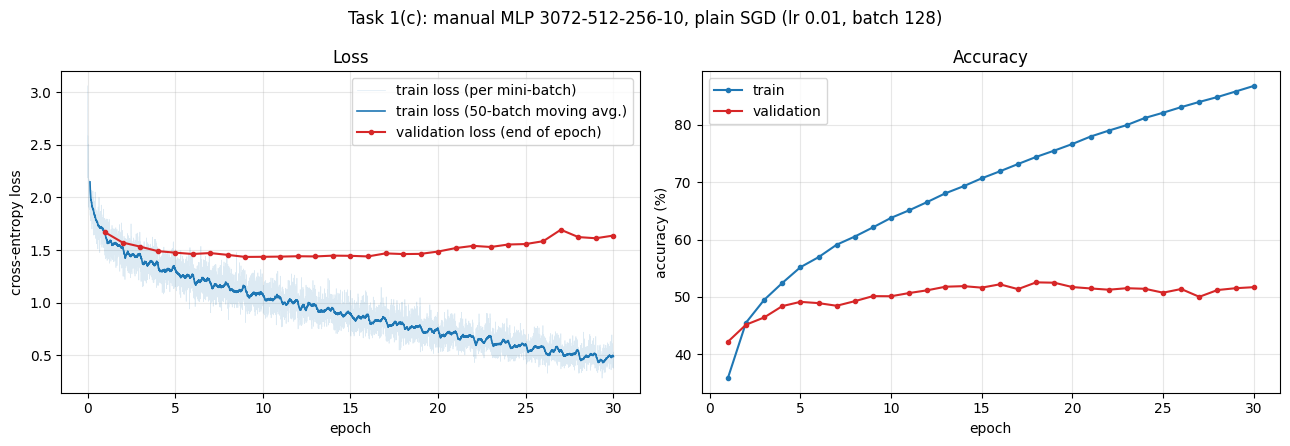

final validation accuracy : 51.70%  (epoch 30)
best  validation accuracy : 52.54%  (epoch 18)
lowest validation loss    : 1.4341  (epoch 9)
final train accuracy      : 86.79%


In [ ]:
iters_per_epoch = len(hist['iter_loss']) // len(hist['train_loss'])
epochs = np.arange(1, len(hist['train_loss']) + 1)
it_ep = np.arange(1, len(hist['iter_loss']) + 1) / iters_per_epoch
smooth = np.convolve(hist['iter_loss'], np.ones(50) / 50, mode='valid')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(it_ep, hist['iter_loss'], color='C0', alpha=0.15, lw=0.5, label='train loss (per mini-batch)')
ax[0].plot(it_ep[49:], smooth, color='C0', lw=1.2, label='train loss (50-batch moving avg.)')
ax[0].plot(epochs, hist['val_loss'], 'o-', color='C3', ms=3, label='validation loss (end of epoch)')
ax[0].set_xlabel('epoch'); ax[0].set_ylabel('cross-entropy loss'); ax[0].set_title('Loss')
ax[0].legend(); ax[0].grid(alpha=0.3)

ax[1].plot(epochs, np.array(hist['train_acc']) * 100, 'o-', ms=3, label='train')
ax[1].plot(epochs, np.array(hist['val_acc']) * 100, 'o-', ms=3, color='C3', label='validation')
ax[1].set_xlabel('epoch'); ax[1].set_ylabel('accuracy (%)'); ax[1].set_title('Accuracy')
ax[1].legend(); ax[1].grid(alpha=0.3)
fig.suptitle('Task 1(c): manual MLP 3072-512-256-10, plain SGD (lr 0.01, batch 128)')
plt.tight_layout(); plt.show()

best = int(np.argmax(hist['val_acc']))
print(f'final validation accuracy : {hist["val_acc"][-1] * 100:.2f}%  (epoch {len(epochs)})')
print(f'best  validation accuracy : {hist["val_acc"][best] * 100:.2f}%  (epoch {best + 1})')
print(f'lowest validation loss    : {min(hist["val_loss"]):.4f}  (epoch {int(np.argmin(hist["val_loss"])) + 1})')
print(f'final train accuracy      : {hist["train_acc"][-1] * 100:.2f}%')

**Interpretation.**

| | epoch 1 | epoch 9 (lowest val loss) | epoch 18 (best val acc) | epoch 30 (final) |
|---|---|---|---|---|
| train loss | 1.814 | 1.118 | 0.794 | 0.463 |
| val loss | 1.669 | **1.434** | 1.461 | 1.638 |
| train acc (%) | 35.8 | 62.1 | 74.4 | 86.8 |
| val acc (%) | 42.2 | 50.1 | **52.5** | 51.7 |

* **The manual backpropagation trains the network.** The training loss falls steadily from 1.81 (epoch-1 mean) to 0.46 at epoch 30, and validation accuracy rises from 42% after one epoch to a best of **52.5%** (epoch 18), far above the 10% chance level. Since every gradient comes from the hand-written backward passes of 1(a), this confirms in practice what 1(b) showed numerically. Each epoch takes only about 0.4 s on the T4, because the whole pass is a handful of large matrix multiplications on GPU-resident data.
* **Starting loss.** The per-batch loss starts near 3, *above* $\ln 10 = 2.30$, the loss of a uniform guess. He initialisation keeps the activation variance at about 1 through every layer, including the output layer. The initial logits are therefore random values of order 1, so the untrained network is *confidently* wrong rather than uniform. SGD removes this within the first few hundred steps. The per-batch curve is noisy because each step sees only 128 images. The 50-batch moving average shows the trend.
* **Train accuracy below validation accuracy in epoch 1 (35.8% vs 42.2%).** This is a measurement effect, not a contradiction. Training accuracy is averaged *during* the epoch, while the model is still improving from random. Validation accuracy is measured once, at the end of the epoch.
* **Overfitting after about epoch 9.**
  * **Validation loss** reaches its minimum of 1.434 at epoch 9 and then rises to 1.64 by epoch 30, while the training loss keeps falling (1.12 → 0.46).
  * **Accuracy gap:** training accuracy climbs almost linearly to 86.8%, but validation accuracy levels off at about 51–52.5% from epoch 13. The final gap is **35 points**.
  * **Why the network can memorise:** with 1.7 M parameters, 45k training images and no regularisation, it fits the training images more and more closely, and that no longer generalises.
  * **Why validation accuracy holds while validation loss rises:** the model mostly keeps its correct predictions but becomes increasingly *over-confident* on the validation images it gets wrong. Cross-entropy penalises such confident mistakes heavily, but accuracy only counts the arg-max.
  * **Early stopping:** stopping at the validation-loss minimum (epoch 9, 50.1%) or the accuracy peak (epoch 18, 52.5%) would give essentially the same validation accuracy as training for 30 epochs, at a third of the cost.
* **Why an MLP stops at about 52%.** This is typical for an MLP on raw CIFAR-10 pixels. Flattening the image discards its 2-D structure, and every weight in the first layer is tied to one pixel position.
  * **No translation invariance:** a pattern such as an edge or a wheel must be learned separately at every position where it can appear. The 1.57 M first-layer weights are spent on this instead of on reusable features.
  * **What CNNs change:** they share small filters across positions and build features hierarchically, which is why the CNNs in Task 2 reach about 75% under similar training.
  * **Possible improvements for the MLP:** regularisation (weight decay, dropout), data augmentation, or a tuned or decaying learning rate. The learning rate 0.01 was not tuned. These would mainly narrow the gap, not remove the architectural limit.

## Task 1(d): Per-layer gradient norms of a 10-layer MLP at initialisation

The network has 10 Linear layers (3072 → 256 → … → 256 → 10, with 9 activations). It is built with sigmoid and with ReLU activations. Each version is initialised, given one forward/backward pass on a batch of 1 000 training images, and nothing more. The plots show:

* **Left:** $\lVert \partial L/\partial W_l \rVert_F$ for each layer $l$. This is the quantity SGD uses to update $W_l$.
* **Right:** $\lVert \partial L/\partial z_l \rVert_F$, the backpropagated error signal at each layer's pre-activation $z_l$.

Two initialisations are shown. The main comparison uses each activation's standard initialisation: **sigmoid + Xavier** and **ReLU + He**. The swapped pairs (sigmoid + He and ReLU + Xavier) show which effects come from the activation and which come from the initialisation. Each curve is averaged over 5 random initialisations; the shaded band shows the minimum–maximum range.

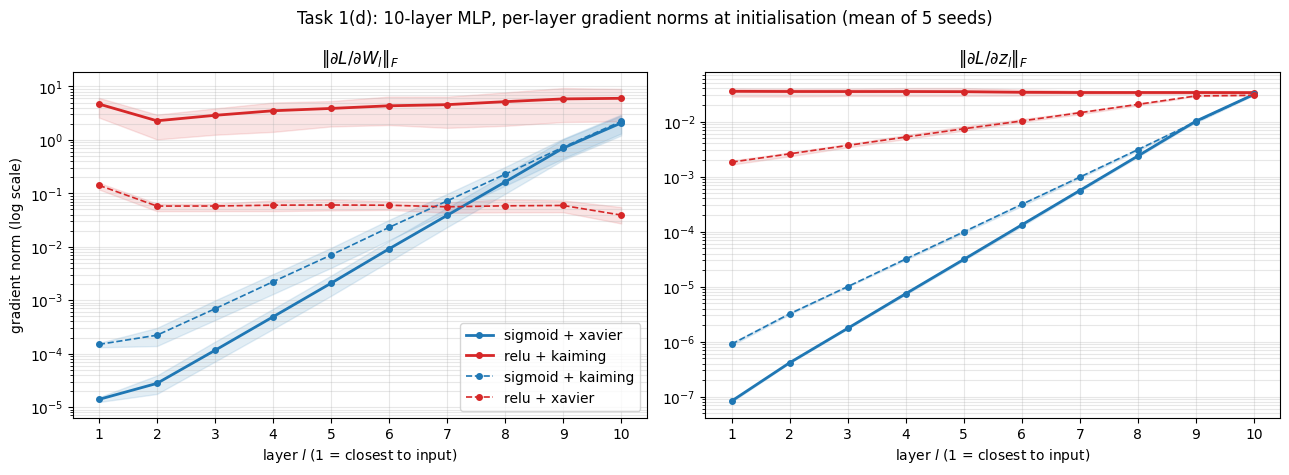

              config |   ||dW_1||  ||dW_10||  ratio 1/10 |   ||dz_1||  ||dz_10||  ratio 1/10
    sigmoid + xavier |   1.39e-05   2.07e+00    6.72e-06 |   8.34e-08   3.11e-02    2.68e-06
      relu + kaiming |   4.69e+00   6.00e+00    7.82e-01 |   3.54e-02   3.36e-02    1.05e+00
   sigmoid + kaiming |   1.49e-04   2.23e+00    6.69e-05 |   9.03e-07   3.12e-02    2.90e-05
       relu + xavier |   1.41e-01   3.92e-02    3.61e+00 |   1.83e-03   3.00e-02    6.10e-02


In [ ]:
def grad_norms_at_init(activation, init, seed, depth=10, width=256, n=1000):
    set_seed(seed)
    mlp = MLP([3072] + [width] * (depth - 1) + [10], activation=activation, init=init, device=device)
    x, y = Xtr[:n], ytr[:n]
    mlp.loss_fn.forward(mlp.forward(x), y)
    grad = mlp.loss_fn.backward()
    delta_norms = []
    for layer in reversed(mlp.layers):            # manual backward, recording dL/dz at each Linear output
        if isinstance(layer, Linear):
            delta_norms.append(grad.norm().item())
        grad = layer.backward(grad)
    w_norms = [l.dW.norm().item() for l in mlp.linears]
    return np.array(w_norms), np.array(delta_norms[::-1])


configs = [('sigmoid', 'xavier', 'C0', '-'), ('relu', 'kaiming', 'C3', '-'),
           ('sigmoid', 'kaiming', 'C0', '--'), ('relu', 'xavier', 'C3', '--')]
results = {}
for act, init, _, _ in configs:
    runs = [grad_norms_at_init(act, init, seed) for seed in range(5)]
    results[(act, init)] = (np.stack([r[0] for r in runs]), np.stack([r[1] for r in runs]))

layers = np.arange(1, 11)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for act, init, c, ls in configs:
    for k, title in enumerate([r'$\|\partial L/\partial W_l\|_F$', r'$\|\partial L/\partial z_l\|_F$']):
        vals = results[(act, init)][k]
        ax[k].plot(layers, vals.mean(0), ls, color=c, marker='o', ms=4,
                   lw=2 if ls == '-' else 1.2, label=f'{act} + {init}')
        ax[k].fill_between(layers, vals.min(0), vals.max(0), color=c, alpha=0.12)
        ax[k].set_title(title); ax[k].set_yscale('log'); ax[k].set_xticks(layers)
        ax[k].set_xlabel('layer $l$ (1 = closest to input)'); ax[k].grid(alpha=0.3, which='both')
ax[0].set_ylabel('gradient norm (log scale)')
ax[0].legend()
fig.suptitle('Task 1(d): 10-layer MLP, per-layer gradient norms at initialisation (mean of 5 seeds)')
plt.tight_layout(); plt.show()

print(f'{"config":>20} | {"||dW_1||":>10} {"||dW_10||":>10} {"ratio 1/10":>11} | {"||dz_1||":>10} {"||dz_10||":>10} {"ratio 1/10":>11}')
for act, init, _, _ in configs:
    w, d = (v.mean(0) for v in results[(act, init)])
    print(f'{act + " + " + init:>20} | {w[0]:10.2e} {w[-1]:10.2e} {w[0] / w[-1]:11.2e} | {d[0]:10.2e} {d[-1]:10.2e} {d[0] / d[-1]:11.2e}')

**Interpretation.**

**Theory.** Backpropagation through one hidden layer computes

$$
\delta_{l} = (\delta_{l+1} W_{l+1}^\top) \odot f'(z_{l}), \qquad \frac{\partial L}{\partial W_l} = h_{l-1}^\top \delta_l ,
$$

where $\delta_l = \partial L/\partial z_l$. With $n$ units per layer, each layer multiplies the norm of $\delta$ by about $\sqrt{n\,\mathrm{Var}(W)\,\mathbb{E}[f'(z)^2]}$. Over the 9 hidden layers, $\lVert\delta_1\rVert/\lVert\delta_{10}\rVert$ is that factor to the 9th power. I compare this with the measured factor $(\text{ratio})^{1/9}$:

| configuration | $\lVert\partial L/\partial W_1\rVert \,/\, \lVert\partial L/\partial W_{10}\rVert$ | $\lVert\delta_1\rVert/\lVert\delta_{10}\rVert$ | measured factor per layer | predicted factor per layer |
|---|---|---|---|---|
| sigmoid + Xavier | $6.7\times10^{-6}$ | $2.7\times10^{-6}$ | **0.240** | $\approx\sigma'(0) = 0.25$, slightly less because $|z| > 0$ |
| sigmoid + He | $6.7\times10^{-5}$ | $2.9\times10^{-5}$ | **0.313** | $\sqrt{2\,\mathbb{E}[\sigma'^2]} \approx 0.31$ |
| ReLU + Xavier | $3.6$ | $6.1\times10^{-2}$ | **0.733** | $\sqrt{1 \cdot \tfrac12} = 0.707$ |
| ReLU + He | $0.78$ | $1.05$ | **1.005** | $\sqrt{2 \cdot \tfrac12} = 1$ |

The measured factors agree with these simple variance calculations to within a few percent. The narrow shaded bands show the pattern is the same for all 5 random initialisations, so it is systematic rather than seed noise. In the right-hand plot all four curves start from the same value at layer 10 (about $3\times10^{-2}$). This is the softmax cross-entropy gradient $(p - \text{onehot}(y))/N$, which does not depend on the hidden activation: with $N = 1000$ its norm is about $\sqrt{N}\cdot 0.95/N \approx 0.03$.

* **Sigmoid: severe vanishing gradients.** $\sigma'(z) = \sigma(z)(1-\sigma(z)) \le 0.25$. With Xavier initialisation, $n\,\mathrm{Var}(W) \approx 1$ for the 256×256 layers, so each sigmoid layer scales the backpropagated signal by about 0.24, and the measured value is exactly that. Over 9 layers this compounds to $0.24^9 \approx 2.7\times10^{-6}$. On the log plot this is a straight line falling about 0.6 decades per layer.
  * **First layer:** it receives a weight gradient of $1.4\times10^{-5}$, against 2.1 for the last layer, about **150 000 times smaller**. Any learning rate that is stable for the last layer would leave the first layers essentially frozen. They would stay near their random initial values and act as a fixed random projection. Such a network trains very slowly, if at all.
  * **He initialisation does not fix it** (dashed blue). Doubling $\mathrm{Var}(W)$ raises the factor only to 0.31, and the first layer's gradient is still $6.7\times10^{-5}$ of the last layer's. Since $\mathbb{E}[\sigma'^2] \le 1/16$, no reasonable weight scale can bring the factor back to 1. The problem is the activation function, not the initialisation.
* **ReLU + He: a flat profile.** $\mathrm{ReLU}'(z)$ is 1 for the roughly half of the units that are active and 0 otherwise, so $\mathbb{E}[f'^2] = \tfrac12$. He initialisation sets $\mathrm{Var}(W) = 2/n$, which cancels this exactly: $n \cdot \frac2n \cdot \frac12 = 1$.
  * **Error signal:** the measured $\lVert\delta_l\rVert$ is constant to within 5% across all 10 layers ($3.54\times10^{-2}$ at layer 1, $3.36\times10^{-2}$ at layer 10).
  * **Weight gradients:** $\lVert\partial L/\partial W_l\rVert$ stays within a factor of about 2.6 (between 2.3 and 6.0). Every layer therefore learns at a similar rate, which is the purpose of He initialisation.
  * **Layer 1 is higher than layer 2** (4.7 vs 2.3) because its input $h_0$ is the 3072-dimensional normalised image rather than a 256-dimensional hidden activation, so $\lVert h_0\rVert$ is larger.
* **ReLU + Xavier: mild vanishing, plus a useful subtlety.** Xavier gives $\mathrm{Var}(W) \approx 1/n$ here, half of He's. The error signal therefore shrinks by about $1/\sqrt2$ per layer (measured 0.733), giving $0.73^9 \approx 0.06$ over the network. This is real but far milder than with sigmoid.
  * **The weight gradients do not fall towards the input.** They are flat at about 0.06 for layers 2–9, and $\lVert\partial L/\partial W_1\rVert$ is even 3.6× *larger* than $\lVert\partial L/\partial W_{10}\rVert$.
  * **Why:** $\partial L/\partial W_l = h_{l-1}^\top\delta_l$ depends on the forward activations as well as on $\delta$. Under Xavier with ReLU, the *forward* activations also shrink by about $1/\sqrt2$ per layer, in the opposite direction. The two effects roughly cancel in the product.
  * **Lesson:** the weight gradient alone can hide a problem in the backward signal, which is why both panels are plotted.
* **Sigmoid weight gradients follow the error signal.** Sigmoid outputs lie in $(0, 1)$ with mean about 0.5 at every layer, so $\lVert h_{l-1}\rVert$ is roughly constant. The weight-gradient curve therefore tracks the $\delta$ curve. Layer 1 is again slightly higher because its input is the image.

**Conclusion.** Gradient flow through depth is governed by the per-layer factor $n\,\mathrm{Var}(W)\,\mathbb{E}[f'^2]$, and the measurements match the predictions of this simple calculation.
* **Sigmoid:** $\sigma' \le \tfrac14$ makes the factor about 0.24, so gradients vanish exponentially with depth, and initialisation cannot compensate.
* **ReLU with He initialisation:** the factor is exactly 1, so the gradient scale is preserved through all 10 layers.

This is why deep networks use ReLU-type activations with variance-preserving initialisation. Batch normalisation and residual connections (Task 3) go further and keep gradients well scaled even in much deeper networks.